# PROJECT A — CNN FROM SCRATCH: CIFAR-10 IMAGE CLASSIFIER

Task A1: Data Loading, EDA & Preprocessing

A1.1
Load CIFAR-10

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

# (X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

# print("X_train shape:", X_train.shape)
# print("y_train shape:", y_train.shape)
# print("X_test shape:", X_test.shape)
# print("y_test shape:", y_test.shape)

# print("Unique labels:", np.unique(y_train))
# print("Data type:", X_train.dtype)

In [3]:
import os
import numpy as np
from tensorflow import keras

dataset_path = '/content/drive/MyDrive/datasets/cifar10.npz'

if os.path.exists(dataset_path):
    data = np.load(dataset_path)
    X_train = data['X_train']
    y_train = data['y_train']
    X_test = data['X_test']
    y_test = data['y_test']

else:
    (X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

    os.makedirs(os.path.dirname(dataset_path), exist_ok=True)

    np.savez_compressed(
        dataset_path,
        X_train=X_train,
        y_train=y_train,
        X_test=X_test,
        y_test=y_test
    )

print("Dataset loaded successfully!")
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

Dataset loaded successfully!
X_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)
X_test shape: (10000, 32, 32, 3)
y_test shape: (10000, 1)


A1.2
Visualise sample images

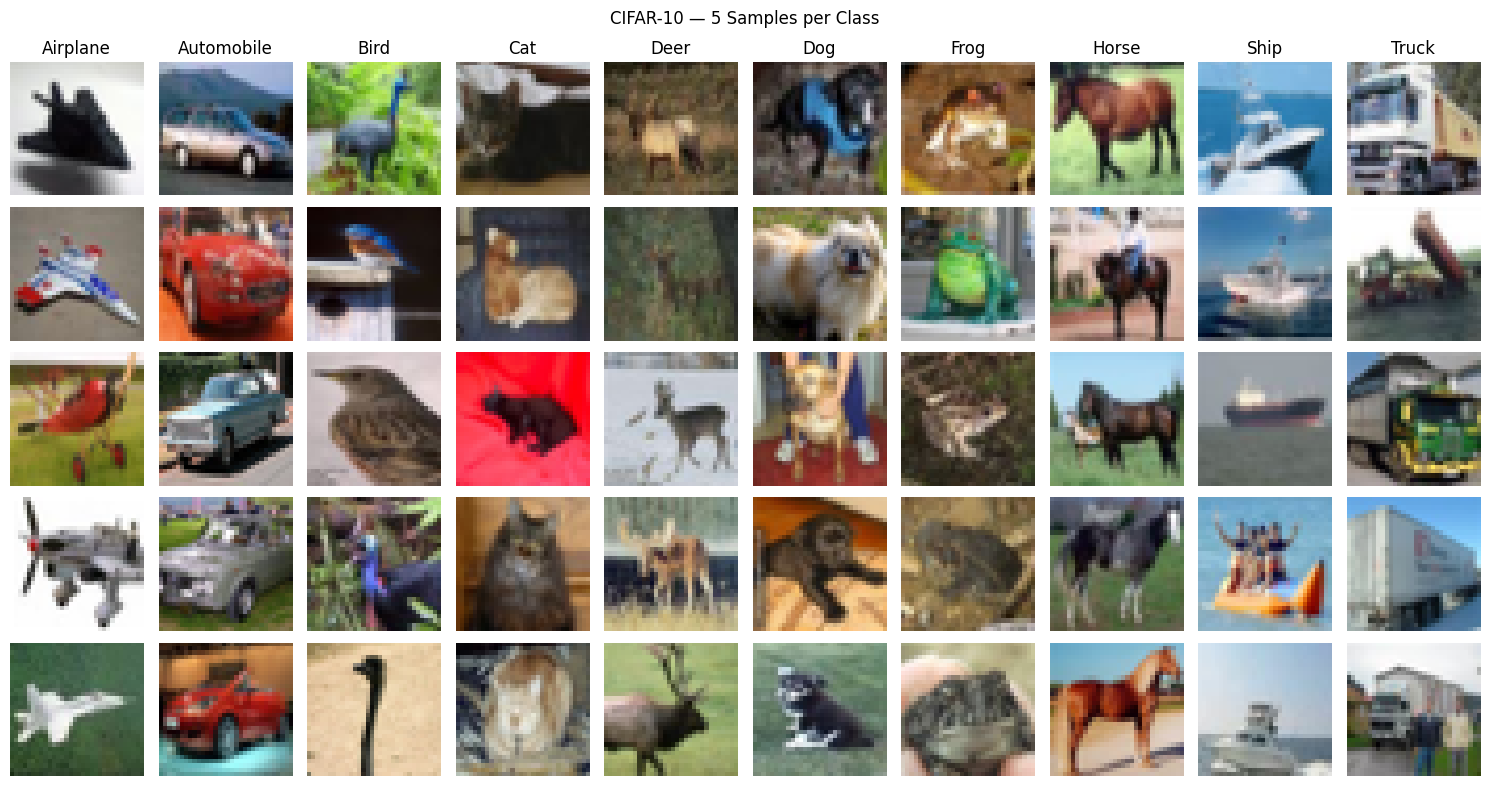

In [4]:
class_names = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer','Dog', 'Frog', 'Horse', 'Ship', 'Truck']

plt.figure(figsize=(15, 8))

for class_id in range(10):
    images = X_train[y_train.flatten() == class_id][:5]

    for row in range(5):
        plt.subplot(5, 10, row * 10 + class_id + 1)
        plt.imshow(images[row])
        plt.axis('off')

        if row == 0:
            plt.title(class_names[class_id])

plt.suptitle("CIFAR-10 — 5 Samples per Class")
plt.tight_layout()
plt.show()

A1.3
Pixel distribution & normalisation

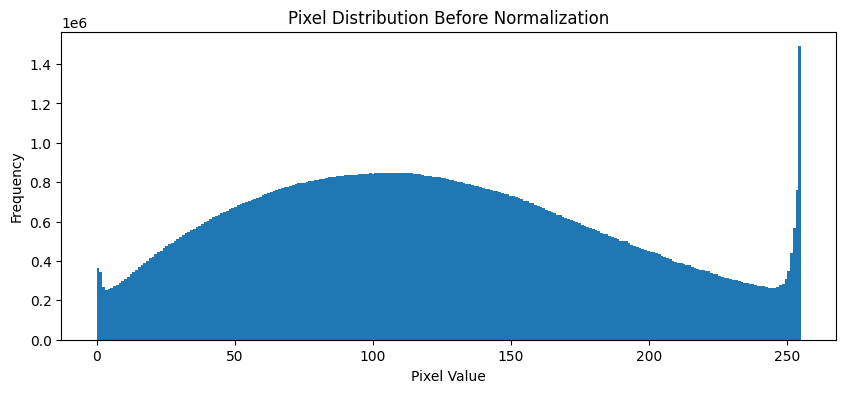

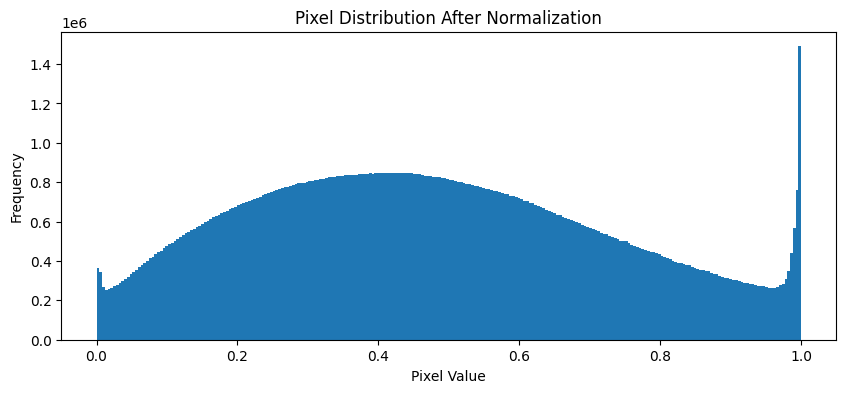

Minimum pixel value: 0.0
Maximum pixel value: 1.0
Data type after normalization: float32


In [5]:
plt.figure(figsize=(10, 4))
plt.hist(X_train.flatten(), bins=256)
plt.title("Pixel Distribution Before Normalization")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.show()

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

plt.figure(figsize=(10, 4))
plt.hist(X_train.flatten(), bins=256)
plt.title("Pixel Distribution After Normalization")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.show()

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())
print("Data type after normalization:", X_train.dtype)

A1.4 One-hot encode labels

In [6]:
y_train_ohe = keras.utils.to_categorical(y_train, 10)
y_test_ohe = keras.utils.to_categorical(y_test, 10)

print("Original labels shape:", y_train.shape)
print("Encoded labels shape:", y_train_ohe.shape)
print("Original label:", y_train[0])
print("One-hot encoded label:", y_train_ohe[0])

Original labels shape: (50000, 1)
Encoded labels shape: (50000, 10)
Original label: [6]
One-hot encoded label: [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


Task A2: Convolution Operation, Padding & Strides

A2.1 Manual convolution demo

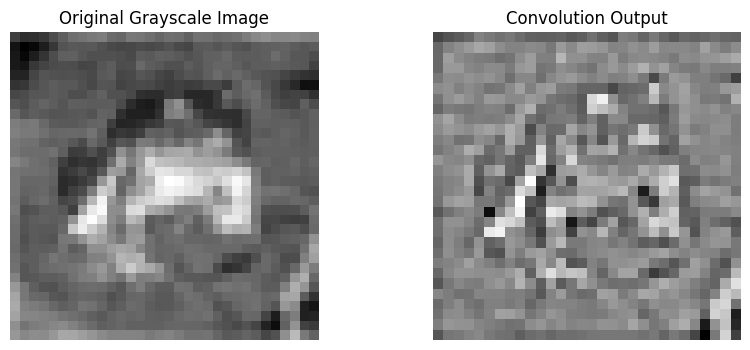

In [7]:
import scipy.signal

gray = np.mean(X_train[0], axis=2)

kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

conv_output = scipy.signal.convolve2d(gray, kernel, mode='valid')

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(conv_output, cmap='gray')
plt.title("Convolution Output")
plt.axis('off')

plt.show()

A2.2 Padding — VALID vs SAME

In [8]:
test_image = X_train[0:1]

model_valid = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(8, (3, 3), padding='valid')
])

model_same = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(8, (3, 3), padding='same')
])

out_valid = model_valid.predict(test_image, verbose=0)
out_same = model_same.predict(test_image, verbose=0)

print("Input shape:", test_image.shape)
print("VALID output shape:", out_valid.shape)
print("SAME output shape:", out_same.shape)

Input shape: (1, 32, 32, 3)
VALID output shape: (1, 30, 30, 8)
SAME output shape: (1, 32, 32, 8)


Original shape: (32, 32)
Padded shape: (34, 34)


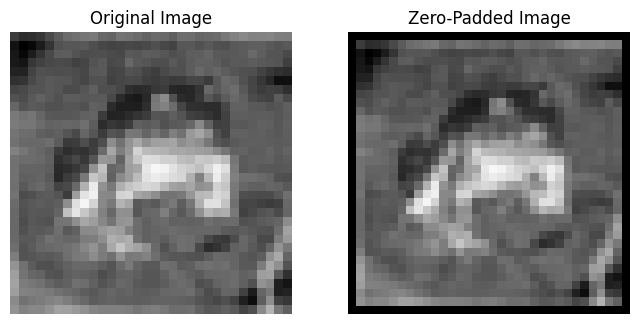

In [9]:
gray_padded = np.pad(gray,pad_width=1,mode='constant',constant_values=0)

print("Original shape:", gray.shape)
print("Padded shape:", gray_padded.shape)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray', vmin=0, vmax=1)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(gray_padded, cmap='gray', vmin=0, vmax=1)
plt.title("Zero-Padded Image")
plt.axis('off')
plt.show()

A2.3 Strides effect

In [10]:
model_stride1 = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(8, (3, 3), strides=1, padding='same')
])

model_stride2 = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(8, (3, 3), strides=2, padding='same')
])

out_stride1 = model_stride1.predict(test_image, verbose=0)
out_stride2 = model_stride2.predict(test_image, verbose=0)
print("Stride 1 output:", out_stride1.shape)
print("Stride 2 output:", out_stride2.shape)

Stride 1 output: (1, 32, 32, 8)
Stride 2 output: (1, 16, 16, 8)


A2.4 Build and visualise feature maps

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Feature maps shape: (1, 32, 32, 16)


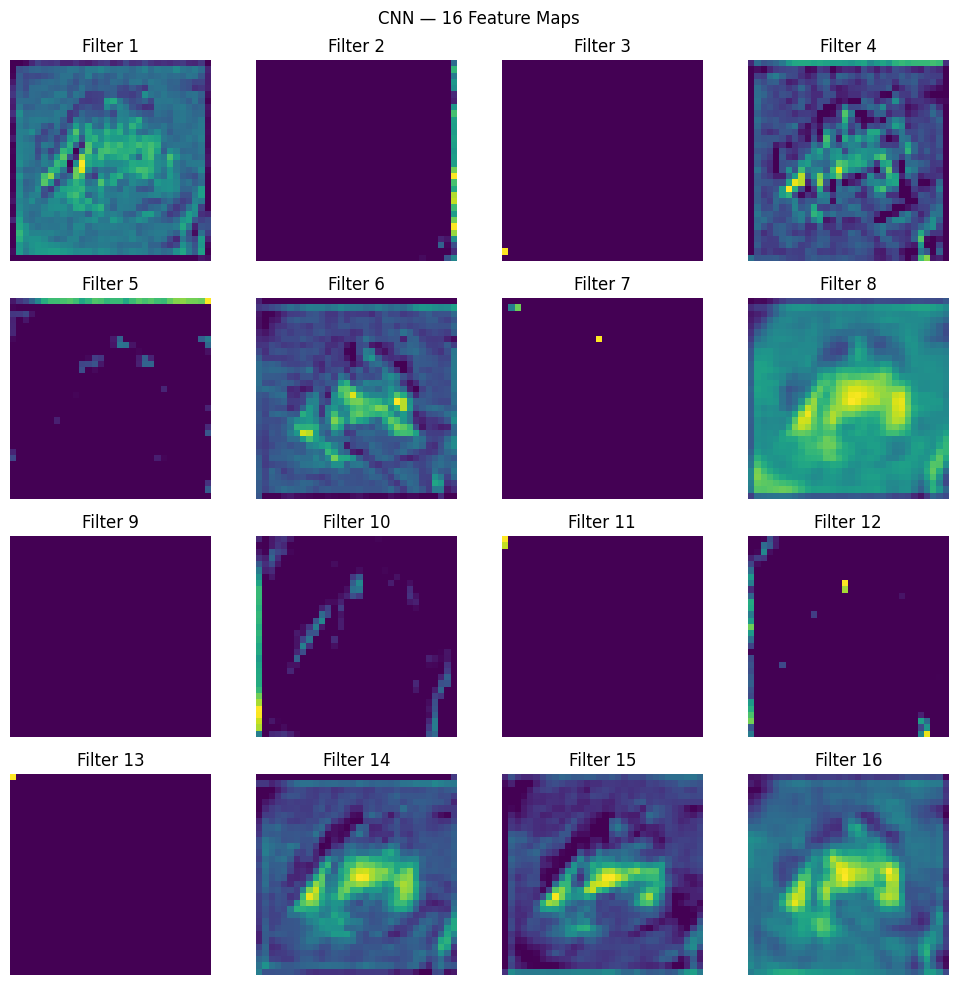

In [11]:
model_vis = keras.Sequential([
    keras.layers.Conv2D(16,(3, 3),activation='relu',padding='same',input_shape=(32, 32, 3))])

feature_maps = model_vis.predict(test_image, verbose=0)
print("Feature maps shape:", feature_maps.shape)

plt.figure(figsize=(10, 10))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap='viridis')
    plt.title(f"Filter {i + 1}")
    plt.axis('off')

plt.suptitle("CNN — 16 Feature Maps")
plt.tight_layout()
plt.show()

Task A4: Backpropagation in CNN & Training

# Backpropagation in CNN

### 1. Forward Pass

During the forward pass, the input image passes through the convolution layers, where learnable filters extract features. Activation functions such as ReLU introduce non-linearity. Pooling layers reduce the spatial dimensions of the feature maps. These operations may repeat through multiple convolution blocks. The feature maps are then flattened into a one-dimensional vector and passed through dense layers. The output layer uses softmax to generate probabilities for the 10 CIFAR-10 classes. The loss function compares the predicted probabilities with the true labels.

### 2. Backward Pass

During backpropagation, the network calculates gradients of the loss with respect to its trainable weights. The chain rule is applied from the output layer back through the dense layers, flattening operation, pooling layers, activation functions, and convolution layers. The optimizer, such as Adam, uses these gradients to update the weights and reduce the loss.

### 3. Gradient Through MaxPooling

In MaxPooling, only the position that contained the maximum value during the forward pass receives the gradient for that pooling window. Other positions receive zero gradient. This is described as routing the gradient through the maximum-value location.

### 4. Gradient Through AveragePooling

In AveragePooling, the upstream gradient is distributed equally among the input positions in each pooling window, according to the averaging operation.

### 5. Gradient Through Flatten

Flatten changes the shape of the feature maps into a one-dimensional vector without changing the underlying values. During backpropagation, the gradient is reshaped to correspond to the original feature-map dimensions.

### Conclusion

Backpropagation allows a CNN to learn useful image features by calculating how each trainable weight contributes to the prediction error. Repeated forward and backward passes gradually improve the model's classification performance.

In [12]:
from tensorflow.keras import layers, models

model_cnn = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.4),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model_cnn.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

A4.2 Compile and train the CNN

In [13]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

model_cnn.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])
es = EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True)
rlrop = ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=3,min_lr=1e-6,verbose=1)
history = model_cnn.fit(X_train,y_train_ohe,epochs=20,batch_size=64,validation_split=0.1,callbacks=[es, rlrop])

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 42s 32ms/step - accuracy: 0.4302 - loss: 1.6729 - val_accuracy: 0.5564 - val_loss: 1.2221 - learning_rate: 0.0010
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6114 - loss: 1.0962 - val_accuracy: 0.6800 - val_loss: 0.9542 - learning_rate: 0.0010
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6795 - loss: 0.9154 - val_accuracy: 0.7092 - val_loss: 0.8101 - learning_rate: 0.0010
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.7185 - loss: 0.8055 - val_accuracy: 0.7278 - val_loss: 0.7871 - learning_rate: 0.0010
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.7453 - loss: 0.7310 - val_accuracy: 0.7604 - val_loss: 0.6989 - learning_rate: 0.0010
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.7696 - loss: 0.6707 - val_accuracy: 0.7926 - val_loss: 0.5936 - learning_rate: 0.0010
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.7867 - loss: 

A4.3 Plot training curves

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9051 - loss: 0.2764 - val_accuracy: 0.8586 - val_loss: 0.4652 - learning_rate: 5.0000e-04
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9070 - loss: 0.2657 - val_accuracy: 0.8604 - val_loss: 0.4592 - learning_rate: 5.0000e-04
Epoch 3/20
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9099 - loss: 0.2574
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9078 - loss: 0.2638 - val_accuracy: 0.8672 - val_loss: 0.4297 - learning_rate: 5.0000e-04
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9183 - loss: 0.2359 - val_accuracy: 0.8762 - val_loss: 0.4175 - learning_rate: 2.5000e-04
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9223 - loss: 0.2207 - val_accuracy: 0.8724 - val_loss: 0.4242 - learning_rate: 2.5000e-04
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy:

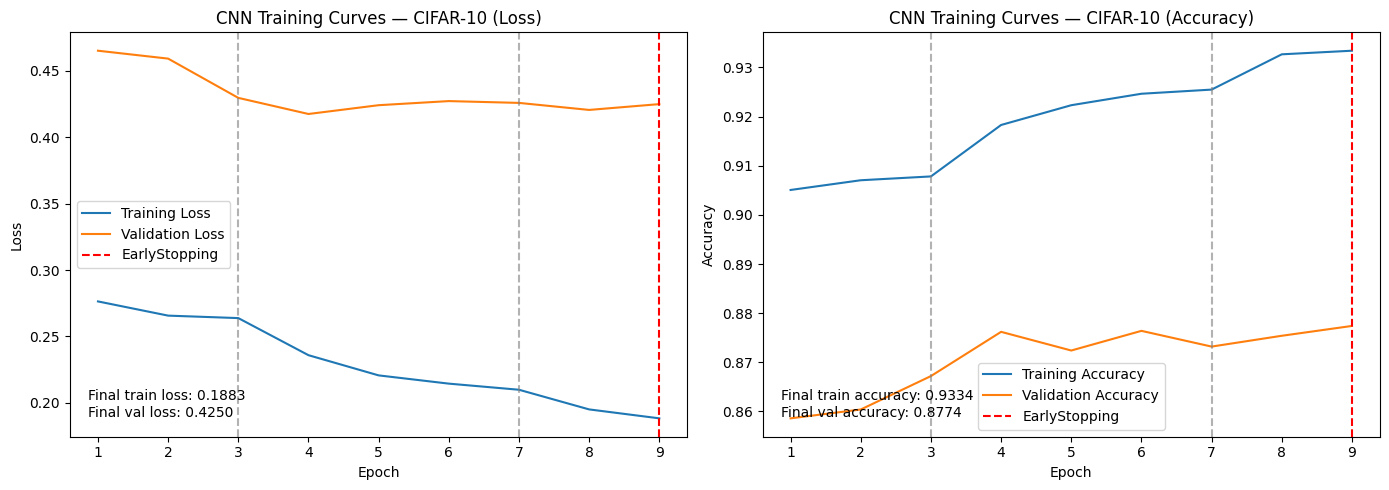

Best validation loss epoch: 4
Last training epoch: 9
Learning rate reduced at epochs: [3, 7]


In [19]:
class LRLogger(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.reduced_epochs = []
        self.previous_lr = float(
            keras.backend.get_value(self.model.optimizer.learning_rate)
        )

    def on_epoch_end(self, epoch, logs=None):
        current_lr = float(
            keras.backend.get_value(self.model.optimizer.learning_rate)
        )

        if current_lr < self.previous_lr:
            self.reduced_epochs.append(epoch + 1)

        self.previous_lr = current_lr


lr_logger = LRLogger()
history = model_cnn.fit(X_train,y_train_ohe,epochs=20,batch_size=64,validation_split=0.1,callbacks=[es, rlrop, lr_logger])

epochs_range = range(1, len(history.history['loss']) + 1)

best_epoch = np.argmin(history.history['val_loss']) + 1
stopped_epoch = len(history.history['loss'])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(epochs_range, history.history['loss'], label='Training Loss')
ax[0].plot(epochs_range, history.history['val_loss'], label='Validation Loss')
ax[0].set_title("Training vs Validation Loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()

ax[1].plot(epochs_range, history.history['accuracy'], label='Training Accuracy')
ax[1].plot(epochs_range, history.history['val_accuracy'], label='Validation Accuracy')
ax[1].set_title("Training vs Validation Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].legend()

for a in ax:
    a.axvline(
        stopped_epoch,
        color='red',
        linestyle='--',
        label='EarlyStopping'
    )

    for epoch in lr_logger.reduced_epochs:
        a.axvline(
            epoch,
            color='gray',
            linestyle='--',
            alpha=0.6
        )

ax[0].set_title("CNN Training Curves — CIFAR-10 (Loss)")
ax[1].set_title("CNN Training Curves — CIFAR-10 (Accuracy)")

ax[0].annotate(
    f"Final train loss: {history.history['loss'][-1]:.4f}\n"
    f"Final val loss: {history.history['val_loss'][-1]:.4f}",
    xy=(0.03, 0.05),
    xycoords='axes fraction'
)

ax[1].annotate(
    f"Final train accuracy: {history.history['accuracy'][-1]:.4f}\n"
    f"Final val accuracy: {history.history['val_accuracy'][-1]:.4f}",
    xy=(0.03, 0.05),
    xycoords='axes fraction'
)

ax[0].legend()
ax[1].legend()
plt.tight_layout()
plt.show()

print("Best validation loss epoch:", best_epoch)
print("Last training epoch:", stopped_epoch)
print("Learning rate reduced at epochs:", lr_logger.reduced_epochs)

In [20]:
# class LRLogger(keras.callbacks.Callback):
#     def on_train_begin(self, logs=None):
#         self.reduced_epochs = []
#         self.previous_lr = float(keras.backend.get_value(self.model.optimizer.learning_rate)        )

#     def on_epoch_end(self, epoch, logs=None):
#         current_lr = float(keras.backend.get_value(self.model.optimizer.learning_rate))

#         if current_lr < self.previous_lr:
#             self.reduced_epochs.append(epoch + 1)

#         self.previous_lr = current_lr

# lr_logger = LRLogger()
# history = model_cnn.fit(X_train,y_train_ohe,epochs=0,batch_size=64,validation_split=0.1,callbacks=[es, rlrop, lr_logger])
# epochs_range = range(1, len(history.history['loss']) + 1)
# best_epoch = np.argmin(history.history['val_loss']) + 1
# stopped_epoch = len(history.history['loss'])

# fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# ax[0].plot(epochs_range, history.history['loss'], label='Training Loss')
# ax[0].plot(epochs_range, history.history['val_loss'], label='Validation Loss')
# ax[0].set_title("Training vs Validation Loss")
# ax[0].set_xlabel("Epoch")
# ax[0].set_ylabel("Loss")
# ax[0].legend()

# ax[1].plot(epochs_range, history.history['accuracy'], label='Training Accuracy')
# ax[1].plot(epochs_range, history.history['val_accuracy'], label='Validation Accuracy')
# ax[1].set_title("Training vs Validation Accuracy")
# ax[1].set_xlabel("Epoch")
# ax[1].set_ylabel("Accuracy")
# ax[1].legend()

# for a in ax:
#     a.axvline(stopped_epoch,color='red',linestyle='--',label='EarlyStopping')
#     for epoch in lr_logger.reduced_epochs:
#         a.axvline(epoch,color='gray',linestyle='--',alpha=0.6)

# ax[0].set_title("CNN Training Curves — CIFAR-10 (Loss)")
# ax[1].set_title("CNN Training Curves — CIFAR-10 (Accuracy)")

# ax[0].annotate(
#     f"Final train loss: {history.history['loss'][-1]:.4f}\n"
#     f"Final val loss: {history.history['val_loss'][-1]:.4f}",
#     xy=(0.03, 0.05),
#     xycoords='axes fraction')

# ax[1].annotate(
#     f"Final train accuracy: {history.history['accuracy'][-1]:.4f}\n"
#     f"Final val accuracy: {history.history['val_accuracy'][-1]:.4f}",
#     xy=(0.03, 0.05),
#     xycoords='axes fraction')

# ax[0].legend()
# ax[1].legend()
# plt.tight_layout()
# plt.show()

# print("Best validation loss epoch:", best_epoch)
# print("Last training epoch:", stopped_epoch)
# print("Learning rate reduced at epochs:", lr_logger.reduced_epochs)

A4.4 Evaluate and analyse

In [21]:
test_loss, test_accuracy = model_cnn.evaluate(X_test,y_test_ohe,verbose=0)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

Test Loss: 0.4396684169769287
Test Accuracy: 0.8676000237464905
Test Accuracy (%): 86.76000237464905


In [22]:
y_pred_prob = model_cnn.predict(X_test, verbose=0)

y_pred = np.argmax(y_pred_prob, axis=1)
y_true = y_test.flatten()
print("Actual labels:", y_true[:10])
print("Predicted labels:", y_pred[:10])

Actual labels: [3 8 8 0 6 6 1 6 3 1]
Predicted labels: [3 8 8 0 6 6 1 6 3 1]


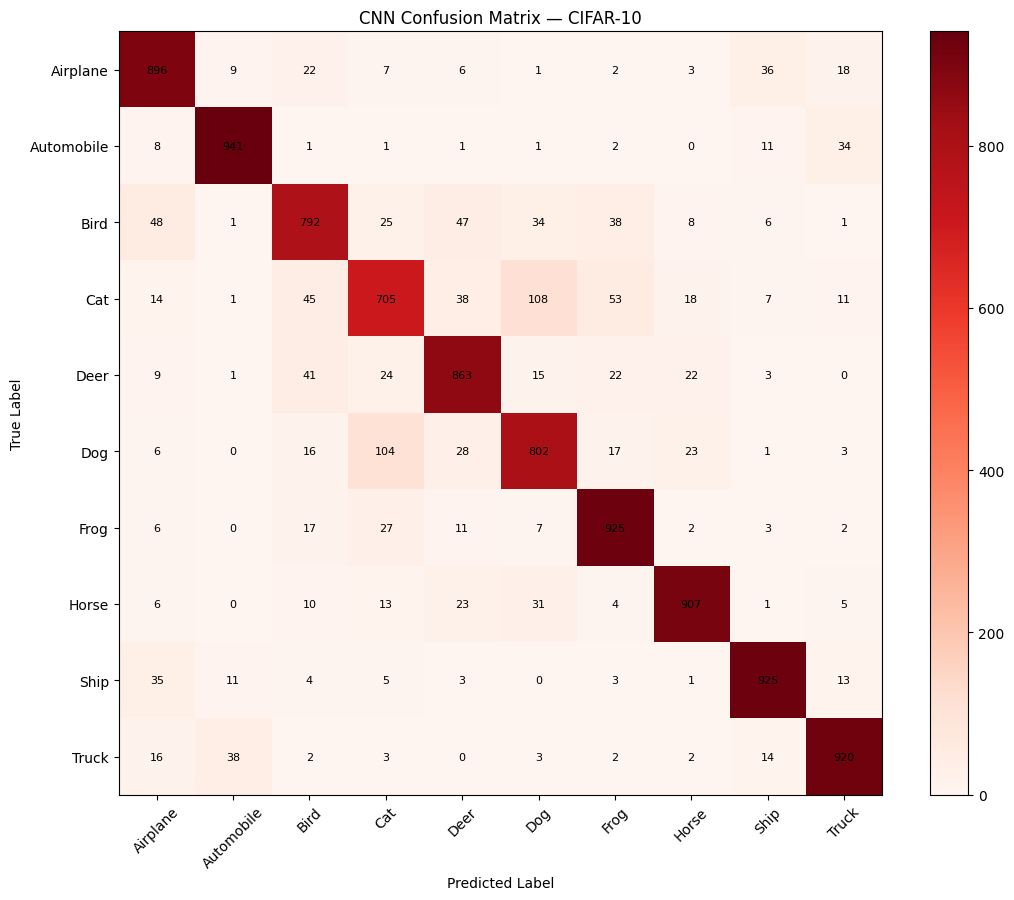

In [23]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true,y_pred,labels=np.arange(10))

plt.figure(figsize=(11, 9))
plt.imshow(cm, cmap='Reds')
plt.colorbar()

plt.xticks(np.arange(10), class_names, rotation=45)
plt.yticks(np.arange(10), class_names)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CNN Confusion Matrix — CIFAR-10")

for i in range(10):
    for j in range(10):
        plt.text(j, i, str(cm[i, j]),ha='center',va='center',fontsize=8)

plt.tight_layout()
plt.show()

In [24]:
pairs = []

for i in range(10):
    for j in range(i + 1, 10):
        confusion_count = cm[i, j] + cm[j, i]
        pairs.append((confusion_count, class_names[i], class_names[j]))

pairs.sort(reverse=True)
print("Top 3 most-confused class pairs:")

for count, class1, class2 in pairs[:3]:
    print(f"{class1} and {class2}: {count} errors")

Top 3 most-confused class pairs:
Cat and Dog: 212 errors
Bird and Deer: 88 errors
Cat and Frog: 80 errors


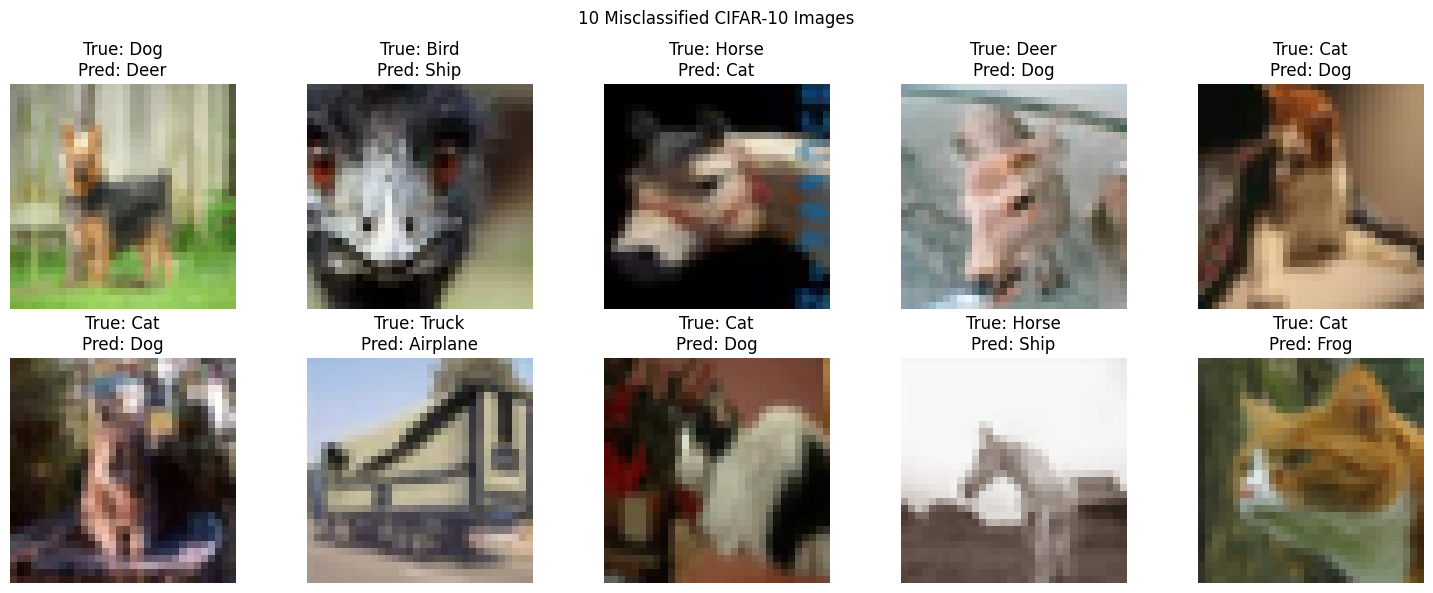

In [25]:
wrong_indices = np.where(y_pred != y_true)[0]
n_images = min(10, len(wrong_indices))
plt.figure(figsize=(15, 6))

for i in range(n_images):
    idx = wrong_indices[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx])

    plt.title(
        f"True: {class_names[y_true[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}"
    )

    plt.axis('off')
plt.suptitle("10 Misclassified CIFAR-10 Images")
plt.tight_layout()
plt.show()

Task A5: Data Augmentation

A5.1 WHY data augmentation — Markdown

# Why Data Augmentation?

A CNN with many trainable parameters trained on a limited number of images may memorize the training data instead of learning general visual patterns. This is called overfitting.

Data augmentation artificially expands the effective training set by applying random transformations to training images, such as rotation, horizontal flipping, shifting, and zooming. The model sees different variations of the same image during training, helping it learn features that remain useful under these transformations.

Data augmentation acts as a regularization technique because it encourages the model to generalize instead of memorizing individual training images. It is especially useful for relatively small image datasets.

For CIFAR-10, augmentation can help the CNN recognize objects despite moderate changes in orientation, position, and scale. However, augmentation must preserve the object's correct class, and excessive transformations can reduce image quality or make classification more difficult.

A5.2 Apply augmentation using ImageDataGenerator

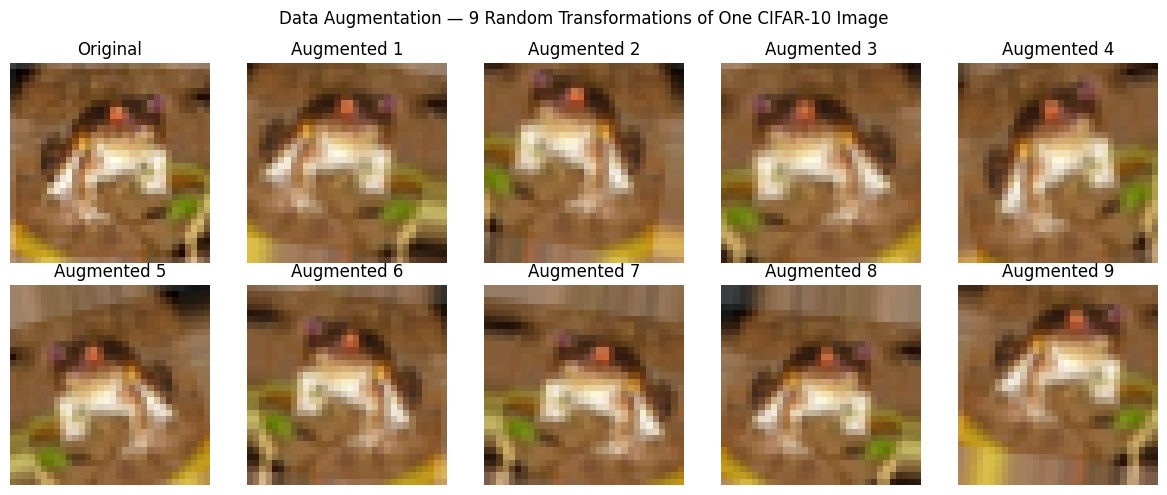

In [26]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    fill_mode='nearest'
)

img = X_train[0]
plt.figure(figsize=(12, 5))

plt.subplot(2, 5, 1)
plt.imshow(img)
plt.title("Original")
plt.axis('off')

augmented_images = datagen.flow(
    img[np.newaxis, ...],
    batch_size=1,
    shuffle=False
)

for i in range(9):
    aug_img = next(augmented_images)[0]

    plt.subplot(2, 5, i + 2)
    plt.imshow(np.clip(aug_img, 0, 1))
    plt.title(f"Augmented {i + 1}")
    plt.axis('off')

plt.suptitle("Data Augmentation — 9 Random Transformations of One CIFAR-10 Image")
plt.tight_layout()
plt.show()

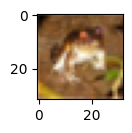

In [27]:
img = X_train[0]
plt.subplot(2, 5, 1)
plt.imshow(img)

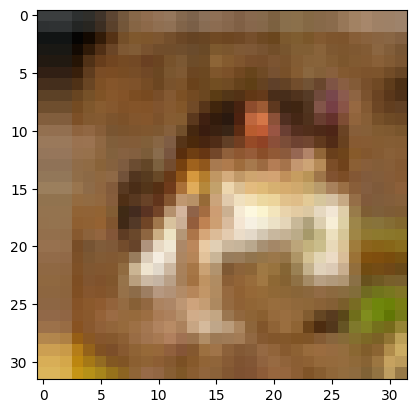

In [28]:
img[np.newaxis, ...]
augmented_images = datagen.flow(
    img[np.newaxis, ...],
    batch_size=1,
    shuffle=False
)

for i in range(9):
    aug_img = next(augmented_images)[0]

plt.imshow(np.clip(aug_img, 0, 1))

A5.3 Retrain CNN with augmentation

In [29]:
from sklearn.model_selection import train_test_split

history_base = history
X_fit, X_val, y_fit, y_val = train_test_split(X_train,y_train_ohe,test_size=0.1,random_state=42,stratify=y_train.flatten())
model_aug = keras.models.clone_model(model_cnn)

model_aug.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

train_generator = datagen.flow(X_fit,y_fit,batch_size=64,shuffle=True)
es_aug = EarlyStopping(monitor='val_loss',patience=10,restore_best_weights=True)
rlrop_aug = ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=5,min_lr=1e-6,verbose=1)
history_aug = model_aug.fit(train_generator,epochs=20,steps_per_epoch=len(X_fit) // 64,validation_data=(X_val, y_val),callbacks=[es_aug, rlrop_aug])

Epoch 1/20
703/703 ━━━━━━━━━━━━━━━━━━━━ 66s 74ms/step - accuracy: 0.3780 - loss: 1.8226 - val_accuracy: 0.5650 - val_loss: 1.2079 - learning_rate: 0.0010
Epoch 2/20
  1/703 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.4531 - loss: 1.4794

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


703/703 ━━━━━━━━━━━━━━━━━━━━ 1s 902us/step - accuracy: 0.4531 - loss: 1.4794 - val_accuracy: 0.5638 - val_loss: 1.2036 - learning_rate: 0.0010
Epoch 3/20
703/703 ━━━━━━━━━━━━━━━━━━━━ 62s 60ms/step - accuracy: 0.5326 - loss: 1.2970 - val_accuracy: 0.5488 - val_loss: 1.2935 - learning_rate: 0.0010
Epoch 4/20
703/703 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5312 - loss: 1.3758 - val_accuracy: 0.5354 - val_loss: 1.3453 - learning_rate: 0.0010
Epoch 5/20
703/703 ━━━━━━━━━━━━━━━━━━━━ 67s 40ms/step - accuracy: 0.6076 - loss: 1.1153 - val_accuracy: 0.6186 - val_loss: 1.1489 - learning_rate: 0.0010
Epoch 6/20
703/703 ━━━━━━━━━━━━━━━━━━━━ 1s 915us/step - accuracy: 0.6562 - loss: 0.9776 - val_accuracy: 0.6194 - val_loss: 1.1337 - learning_rate: 0.0010
Epoch 7/20
703/703 ━━━━━━━━━━━━━━━━━━━━ 31s 44ms/step - accuracy: 0.6489 - loss: 1.0011 - val_accuracy: 0.6826 - val_loss: 0.8876 - learning_rate: 0.0010
Epoch 8/20
703/703 ━━━━━━━━━━━━━━━━━━━━ 1s 890us/step - accuracy: 0.7031 - loss: 0.8177 -

A5.4 Modern augmentation with Keras layers

In [30]:
data_augmentation = keras.Sequential([
    keras.layers.RandomFlip('horizontal'),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
    keras.layers.RandomTranslation(0.1, 0.1)
], name='data_augmentation')

model_modern_core = keras.models.clone_model(model_cnn)

model_modern = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    data_augmentation,
    model_modern_core
])

model_modern.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

es_modern = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

rlrop_modern = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

history_modern = model_modern.fit(X_fit,y_fit,epochs=15,batch_size=64,validation_data=(X_val, y_val),callbacks=[es_modern, rlrop_modern])

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 26s 23ms/step - accuracy: 0.3511 - loss: 1.9083 - val_accuracy: 0.4480 - val_loss: 1.5964 - learning_rate: 0.0010
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 23s 33ms/step - accuracy: 0.4803 - loss: 1.4419 - val_accuracy: 0.5068 - val_loss: 1.4935 - learning_rate: 0.0010
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 26s 36ms/step - accuracy: 0.5378 - loss: 1.2923 - val_accuracy: 0.5614 - val_loss: 1.2502 - learning_rate: 0.0010
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 21s 30ms/step - accuracy: 0.5800 - loss: 1.1866 - val_accuracy: 0.5708 - val_loss: 1.2443 - learning_rate: 0.0010
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 24s 34ms/step - accuracy: 0.6074 - loss: 1.1114 - val_accuracy: 0.6462 - val_loss: 1.0193 - learning_rate: 0.0010
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 32s 21ms/step - accuracy: 0.6309 - loss: 1.0572 - val_accuracy: 0.6440 - val_loss: 1.0271 - learning_rate: 0.0010
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.6470 - l

In [31]:
loss_aug, acc_aug = model_aug.evaluate(
    X_test, y_test_ohe, verbose=0
)
loss_modern, acc_modern = model_modern.evaluate(
    X_test, y_test_ohe, verbose=0
)

print("ImageDataGenerator Test Accuracy:", acc_aug)
print("Keras Layers Test Accuracy:", acc_modern)
print("ImageDataGenerator Accuracy (%):", acc_aug * 100)
print("Keras Layers Accuracy (%):", acc_modern * 100)

ImageDataGenerator Test Accuracy: 0.7657999992370605
Keras Layers Test Accuracy: 0.7588000297546387
ImageDataGenerator Accuracy (%): 76.57999992370605
Keras Layers Accuracy (%): 75.88000297546387


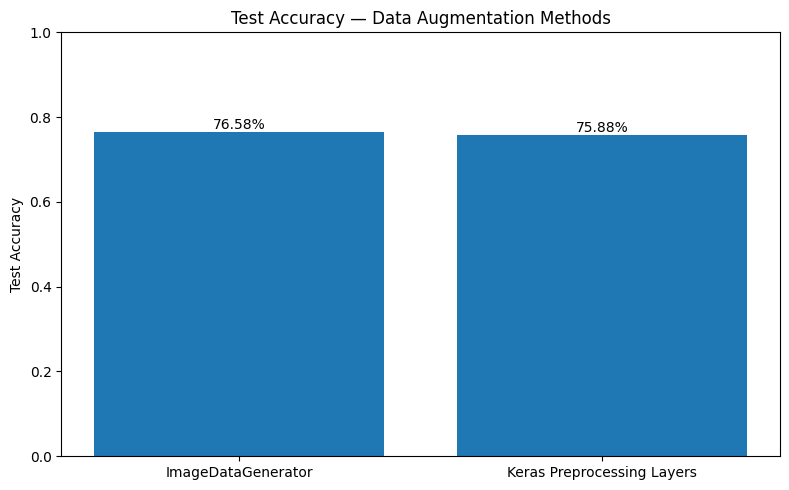

In [32]:
methods = [
    'ImageDataGenerator',
    'Keras Preprocessing Layers'
]

accuracies = [acc_aug, acc_modern]
plt.figure(figsize=(8, 5))
bars = plt.bar(methods, accuracies)

plt.title("Test Accuracy — Data Augmentation Methods")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)

for bar, accuracy in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width() / 2,bar.get_height(),f"{accuracy:.2%}",ha='center',va='bottom')
plt.tight_layout()
plt.show()

Task A6: Transfer Learning — Feature Extraction & Fine-Tuning

A6.1 WHY Transfer Learning — Markdown

# Why Transfer Learning?

Training a deep CNN from scratch on CIFAR-10 requires the model to learn visual features from the available training images. This can require substantial training time and data.

Transfer learning uses a model pre-trained on a large dataset such as ImageNet, which contains millions of images across many classes. The pre-trained model has already learned useful visual features, including edges, textures, shapes, and object parts. These features can be reused for a new image-classification task.

There are two main approaches:

**1. Feature Extraction:** Freeze the pre-trained model's weights and add a new classification head. Train only the new layers. This approach is computationally efficient because most of the network's parameters remain unchanged.

**2. Fine-Tuning:** Unfreeze selected layers of the pre-trained model and train them along with the new classification head using a very low learning rate. This allows the learned features to adapt to the new dataset.

Feature extraction is faster, while fine-tuning can improve performance by adapting the pre-trained features. The best approach depends on the dataset, computational resources, and validation results.

A6.2
Feature Extraction with MobileNetV2

In [1]:
X_train_r = tf.image.resize(X_train, (96, 96)).numpy()
X_test_r = tf.image.resize(X_test, (96, 96)).numpy()

print("Resized training shape:", X_train_r.shape)
print("Resized testing shape:", X_test_r.shape)

NameError: name 'tf' is not defined

In [ ]:
base_model = keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

print("Total layers:", len(base_model.layers))
print("Trainable:", base_model.trainable)

In [ ]:
inputs = keras.Input(shape=(96, 96, 3))

x = keras.applications.mobilenet_v2.preprocess_input(inputs * 255.0)
x = base_model(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dense(128, activation='relu')(x)
outputs = keras.layers.Dense(10, activation='softmax')(x)
model_fe = keras.Model(inputs, outputs)
model_fe.summary()

A6.3
Train feature extraction model

In [ ]:
model_fe.compile(optimizer=keras.optimizers.Adam(0.001),loss='categorical_crossentropy',metrics=['accuracy'])
history_fe = model_fe.fit(X_train_r,y_train_ohe,epochs=20,batch_size=64,validation_split=0.1)

In [ ]:
loss_fe, acc_fe = model_fe.evaluate(X_test_r,y_test_ohe,verbose=0)
print("Feature Extraction Test Loss:", loss_fe)
print("Feature Extraction Test Accuracy:", acc_fe)
print("Test Accuracy (%):", acc_fe * 100)

A6.4
Fine-Tuning

In [ ]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers[-30:]:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

model_fe.compile(optimizer=keras.optimizers.Adam(1e-5),loss='categorical_crossentropy',metrics=['accuracy'])
history_ft = model_fe.fit(X_train_r,y_train_ohe,epochs=10,batch_size=32,validation_split=0.1)

In [ ]:
fe_acc = history_fe.history['accuracy']
ft_acc = history_ft.history['accuracy']

fe_val_acc = history_fe.history['val_accuracy']
ft_val_acc = history_ft.history['val_accuracy']

fe_loss = history_fe.history['loss']
ft_loss = history_ft.history['loss']

fe_val_loss = history_fe.history['val_loss']
ft_val_loss = history_ft.history['val_loss']

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(fe_loss, label='Feature Extraction Train')
plt.plot(fe_val_loss, label='Feature Extraction Validation')
plt.plot(
    range(len(fe_loss), len(fe_loss) + len(ft_loss)),
    ft_loss,
    label='Fine-Tuning Train'
)
plt.plot(
    range(len(fe_val_loss), len(fe_val_loss) + len(ft_val_loss)),
    ft_val_loss,
    label='Fine-Tuning Validation'
)
plt.axvline(len(fe_loss) - 1, color='red', linestyle='--',
            label='Fine-Tuning Starts')
plt.title("Feature Extraction vs Fine-Tuning — Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(fe_acc, label='Feature Extraction Train')
plt.plot(fe_val_acc, label='Feature Extraction Validation')
plt.plot(
    range(len(fe_acc), len(fe_acc) + len(ft_acc)),
    ft_acc,
    label='Fine-Tuning Train'
)
plt.plot(
    range(len(fe_val_acc), len(fe_val_acc) + len(ft_val_acc)),
    ft_val_acc,
    label='Fine-Tuning Validation'
)
plt.axvline(len(fe_acc) - 1, color='red', linestyle='--',
            label='Fine-Tuning Starts')
plt.title("Feature Extraction vs Fine-Tuning — Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

A6.5
Full results comparison table

In [ ]:
import pandas as pd

results = []

def add_result(name, model, architecture, augmentation, transfer, images):
    loss, accuracy = model.evaluate(
        images, y_test_ohe, verbose=0
    )
    results.append({
        'Model': name,
        'Architecture': architecture,
        'Augmentation': augmentation,
        'Transfer Learning': transfer,
        'Test Accuracy': accuracy,
        'Parameters': model.count_params()
    })

if 'model_lenet' in globals():
    add_result('LeNet-5',model_lenet,'LeNet-5','No','No',X_test)

if 'model_cnn' in globals():
    add_result('CNN Scratch No Aug',model_cnn,'CNN','No','No',X_test)

if 'model_aug' in globals():
    add_result('CNN Scratch + Aug',model_aug,'CNN','ImageDataGenerator','No',X_test)

if 'model_modern' in globals():
    add_result('CNN + Keras Aug Layers',model_modern,'CNN','Keras Layers','No',X_test)
if 'model_fe' in globals():
    add_result('MobileNetV2 Fine-Tuned',model_fe,'MobileNetV2','No','Fine-Tuning',X_test_r)

results_df = pd.DataFrame(results)
display(results_df.style.highlight_max(subset=['Test Accuracy'],color='#ffcccc').format({'Test Accuracy': '{:.2%}'}))